<a href="https://colab.research.google.com/github/opaiot/ia-otimizacao-iot-industrias-negocios-public/blob/main/M4/colab/M4_Aplicação_Prática_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

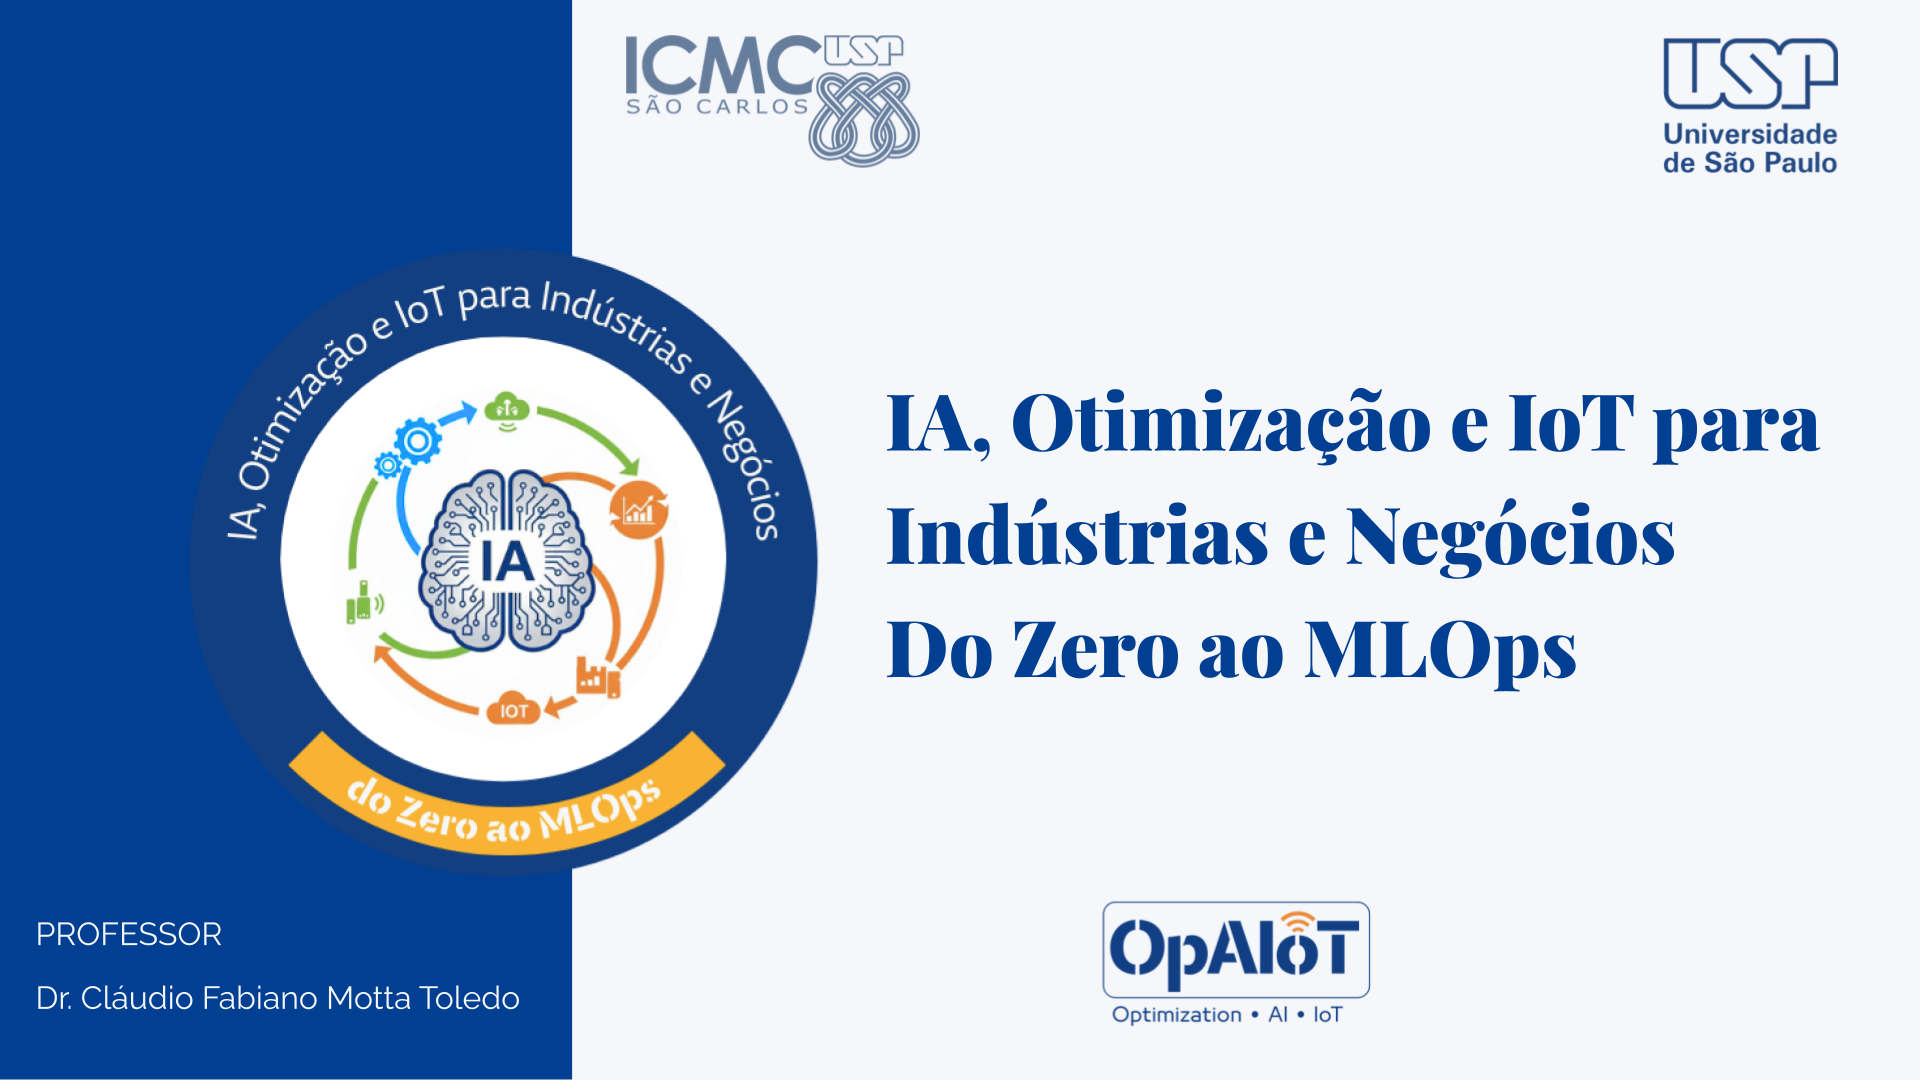

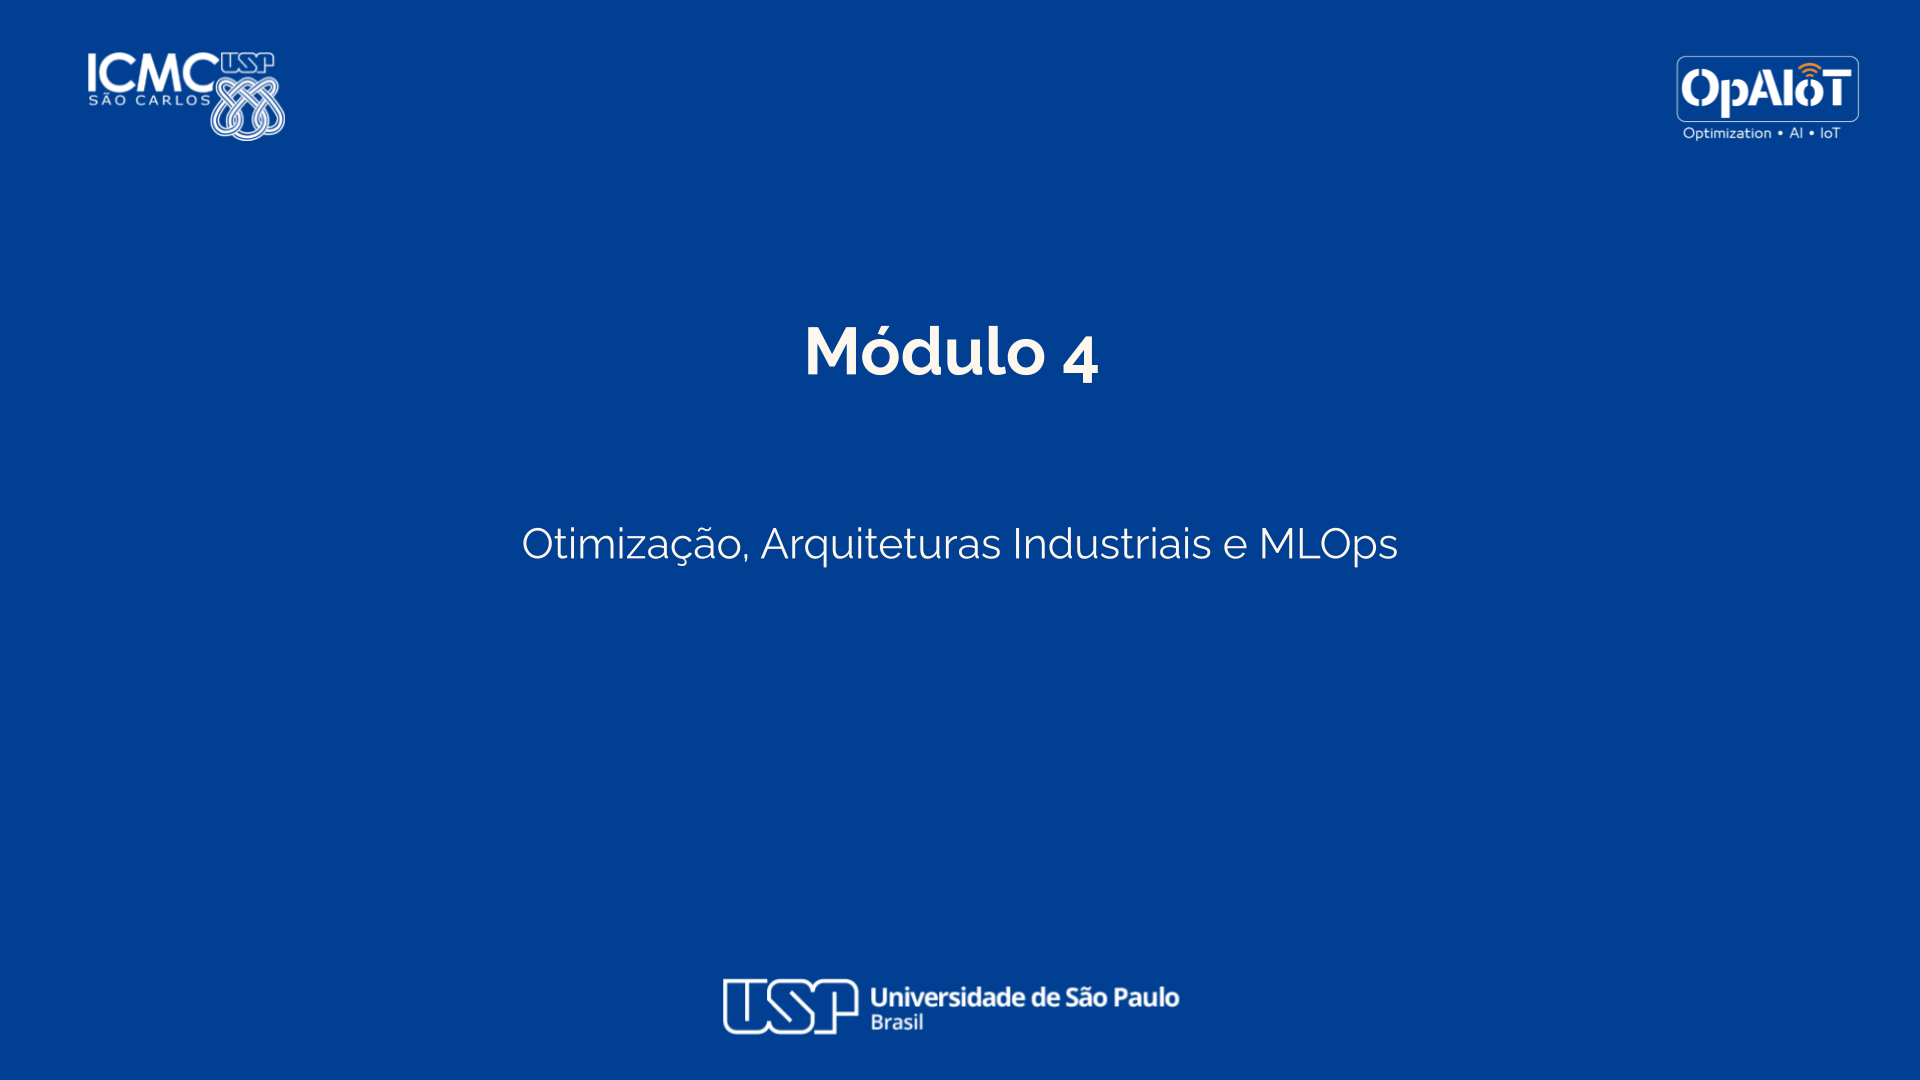

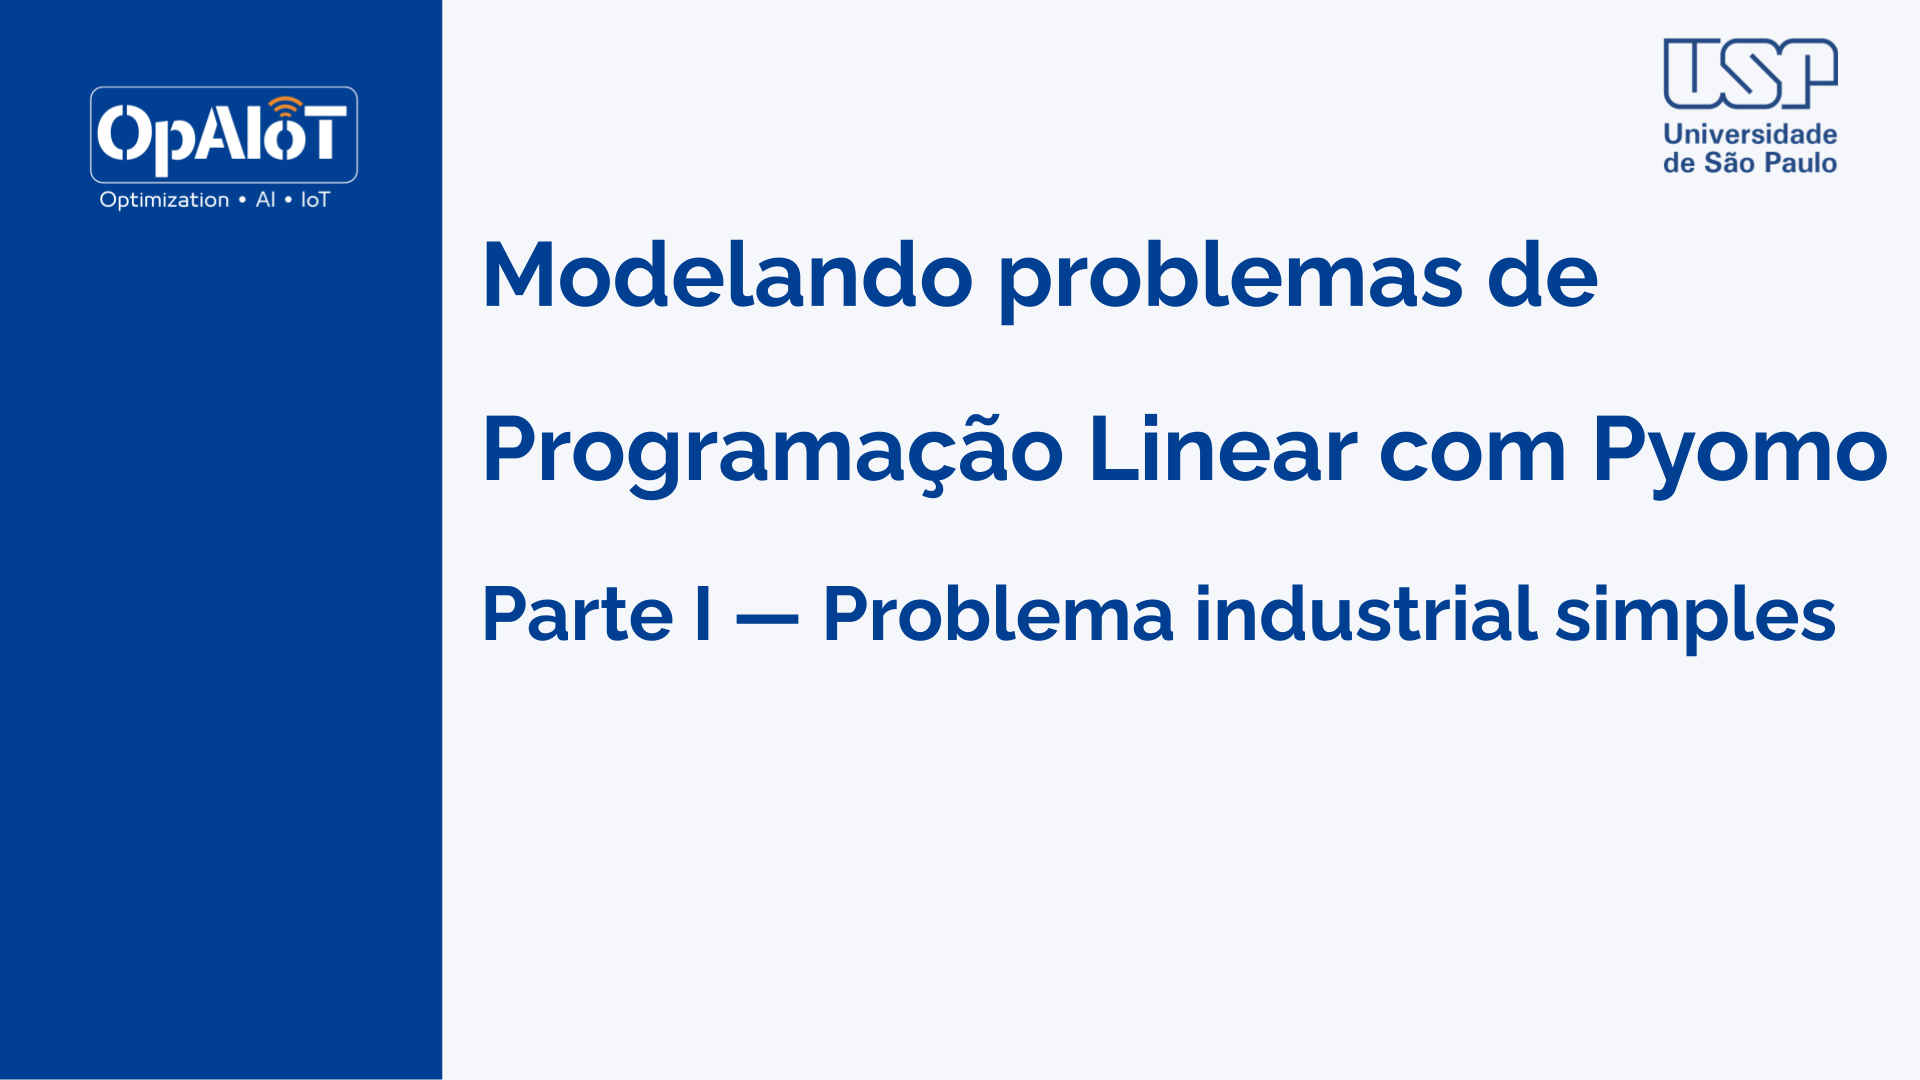

# Modelando problemas de Programação Linear com Pyomo

Este notebook ensina, passo a passo, como transformar problemas industriais em **modelos matemáticos de programação linear** e implementá-los em **Pyomo**.

Pyomo permite escrever modelos de otimização em Python e resolvê-los usando solvers como HiGHS, GLPK, CBC, CPLEX, Gurobi e IPOPT.

A sequência segue três níveis de modelagem:

1. **Problema industrial simples**: dois produtos e duas máquinas, com restrições escritas uma a uma.
2. **Problema industrial geral**: muitos produtos e muitos recursos, usando conjuntos, parâmetros e somatórios.
3. **Problema logístico de transporte**: quanto enviar de cada origem para cada destino ao menor custo.

A ideia principal é mostrar a passagem:

$$
\text{problema real} \rightarrow \text{variáveis} \rightarrow \text{objetivo} \rightarrow \text{restrições} \rightarrow \text{código em Pyomo}
$$

## 1. Instalação e importação das bibliotecas

Usaremos:

- `pyomo`: biblioteca para modelagem matemática;
- `highspy`: interface Python para o solver HiGHS, usado para resolver problemas lineares;
- `pandas`: usado apenas para organizar tabelas e exibir resultados.

No Google Colab, execute a célula abaixo antes das demais.

In [19]:
!pip install -q pyomo highspy pandas
import pyomo.environ as pyo
import pandas as pd

## 2. Receita de formulação em Programação Linear

Antes de codificar, fazemos a formulação matemática. Uma boa sequência é:

| Etapa | Pergunta de modelagem | Exemplo |
|---|---|---|
| Variáveis de decisão | O que será escolhido? | quantidade produzida, enviada ou armazenada |
| Função objetivo | O que será minimizado ou maximizado? | custo, lucro, tempo ou desperdício |
| Restrições | Quais regras devem ser respeitadas? | capacidade, demanda, orçamento, estoque |
| Domínio | Que valores são permitidos? | em PL, variáveis contínuas e não negativas |

# Parte I — Problema industrial simples

## 3. Contexto do problema

Uma fábrica produz dois produtos, **Produto A** e **Produto B**. Cada unidade consome horas de duas máquinas. O objetivo é maximizar o lucro semanal, respeitando a capacidade das máquinas e limites máximos de demanda.

Os dados são:

| Dado | Produto A | Produto B | Disponível |
|---|---:|---:|---:|
| Lucro unitário | R\$ 40 | R\$ 30 | — |
| Máquina 1 | 2 h/unid. | 1 h/unid. | 100 h |
| Máquina 2 | 1 h/unid. | 2 h/unid. | 80 h |
| Demanda máxima | 40 unid. | 50 unid. | — |

Pergunta: **quantas unidades de A e B devemos produzir para obter o maior lucro possível sem violar as capacidades?**

## 4. Formulação matemática do modelo simples

### Variáveis de decisão

$
x_A = \text{unidades produzidas do Produto A}
$

$
x_B = \text{unidades produzidas do Produto B}
$

Como são quantidades contínuas em programação linear:

$
x_A, x_B \geq 0
$

### Função objetivo

Maximizar o lucro total:

$
\max Z = 40x_A + 30x_B
$

### Restrições

Capacidade da Máquina 1:

$
2x_A + x_B \leq 100
$

Capacidade da Máquina 2:

$
x_A + 2x_B \leq 80
$

Demanda máxima:

$
x_A \leq 40
$

$
x_B \leq 50
$

## 5. Implementação em Pyomo — modelo simples

Abaixo implementamos exatamente a formulação anterior.

Observe a correspondência:

- `model.xA` e `model.xB` são as variáveis de decisão;
- `model.obj` representa a função objetivo;
- `model.cap_m1`, `model.cap_m2`, `model.dem_A` e `model.dem_B` são restrições;
- `domain=pyo.NonNegativeReals` impõe não negatividade.

In [20]:
# Criação do modelo
model = pyo.ConcreteModel(name="Producao_simples")

# Variáveis de decisão
model.xA = pyo.Var(domain=pyo.NonNegativeReals)
model.xB = pyo.Var(domain=pyo.NonNegativeReals)

# Função objetivo: maximizar lucro
model.obj = pyo.Objective(
    expr=40 * model.xA + 30 * model.xB,
    sense=pyo.maximize
)

# Restrições de capacidade
model.cap_m1 = pyo.Constraint(expr=2 * model.xA + model.xB <= 100)
model.cap_m2 = pyo.Constraint(expr=model.xA + 2 * model.xB <= 80)

# Restrições de demanda máxima
model.dem_A = pyo.Constraint(expr=model.xA <= 40)
model.dem_B = pyo.Constraint(expr=model.xB <= 50)

# Criar o solver
solver_s = pyo.SolverFactory("appsi_highs")

# Resolver o modelo
resultado = solver_s.solve(model)

# Mostrar status da solução
print("Status:", resultado.solver.status)
print("Condição de término:", resultado.solver.termination_condition)

# Mostrar solução ótima
print("xA =", pyo.value(model.xA))
print("xB =", pyo.value(model.xB))
print("Lucro máximo =", pyo.value(model.obj))

Status: ok
Condição de término: optimal
xA = 40.0
xB = 20.0
Lucro máximo = 2200.0


## 6. Resultado do modelo simples

Depois de resolver o modelo, podemos consultar os valores ótimos das variáveis e da função objetivo.

In [21]:
solucao_simples = pd.DataFrame({
    "Variável": ["xA", "xB", "Lucro total"],
    "Descrição": ["Unidades do Produto A", "Unidades do Produto B", "Valor de Z"],
    "Valor ótimo": [
        pyo.value(model.xA),
        pyo.value(model.xB),
        pyo.value(model.obj)
    ]
})

display(solucao_simples)

,Variável,Descrição,Valor ótimo
0,xA,Unidades do Produto A,40.0
1,xB,Unidades do Produto B,20.0
2,Lucro total,Valor de Z,2200.0


## 7. Leitura do resultado

O resultado informa a melhor combinação de produção dentro das regras do problema.

Para interpretar:

- se uma restrição está no limite, ela é um recurso crítico;
- se uma restrição possui folga, ainda há capacidade ou limite disponível;
- o valor de `Z` é o maior lucro obtido com a combinação escolhida.

Vamos calcular também o uso das máquinas e comparar com a capacidade disponível.

In [22]:
xA = pyo.value(model.xA)
xB = pyo.value(model.xB)

uso_recursos = pd.DataFrame({
    "Restrição": ["Máquina 1", "Máquina 2", "Demanda A", "Demanda B"],
    "Uso calculado": [2*xA + xB, xA + 2*xB, xA, xB],
    "Limite": [100, 80, 40, 50]
})
uso_recursos["Folga"] = uso_recursos["Limite"] - uso_recursos["Uso calculado"]
display(uso_recursos)

,Restrição,Uso calculado,Limite,Folga
0,Máquina 1,100.0,100,0.0
1,Máquina 2,80.0,80,0.0
2,Demanda A,40.0,40,0.0
3,Demanda B,20.0,50,30.0


#Recursos para impressão e criação de arquivo

In [23]:
#Imprimindo o modelo
#model.pprint()      # mostra a estrutura do modelo
model.display()     # mostra valores atuais, útil após resolver
model.xA.pprint()    # mostra uma variável específica
model.obj.pprint()  # mostra a função objetivo
model.write("modelo.lp", io_options={"symbolic_solver_labels": True})  # exporta o modelo

Model Producao_simples

  Variables:
    xA : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  40.0 :  None : False : False : NonNegativeReals
    xB : Size=1, Index=None
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  20.0 :  None : False : False : NonNegativeReals

  Objectives:
    obj : Size=1, Index=None, Active=True
        Key  : Active : Value
        None :   True : 2200.0

  Constraints:
    cap_m1 : Size=1
        Key  : Lower : Body  : Upper
        None :  None : 100.0 : 100.0
    cap_m2 : Size=1
        Key  : Lower : Body : Upper
        None :  None : 80.0 :  80.0
    dem_A : Size=1
        Key  : Lower : Body : Upper
        None :  None : 40.0 :  40.0
    dem_B : Size=1
        Key  : Lower : Body : Upper
        None :  None : 20.0 :  50.0
xA : Size=1, Index=None
    Key  : Lower : Value : Upper : Fixed : Stale : Domain
    None :     0 :  40.0 :  None : False : False : NonN

('modelo.lp', 131965579977376)

# Parte II — Modelo industrial geral

## 8. Por que generalizar?

O modelo simples foi escrito para dois produtos e duas máquinas. Em uma aplicação real, podemos ter:

- muitos produtos;
- muitos recursos produtivos;
- diferentes lucros unitários;
- diferentes consumos de recursos;
- diferentes demandas máximas.

Em vez de escrever uma restrição para cada máquina manualmente, usamos **conjuntos**, **parâmetros indexados** e **somatórios**.

## 9. Elementos do modelo geral

### Conjuntos

$
I = \text{conjunto de produtos}
$

$
R = \text{conjunto de recursos produtivos}
$

### Parâmetros

$
p_i = \text{lucro unitário do produto } i
$

$
a_{ri} = \text{uso do recurso } r \text{ por unidade do produto } i
$

$
b_r = \text{capacidade disponível do recurso } r
$

$
d_i = \text{demanda máxima do produto } i
$

### Variável de decisão

$
x_i = \text{quantidade produzida do produto } i
$

Regra prática: **parâmetros são dados de entrada; variáveis são decisões calculadas pelo modelo.**

## 10. Formulação geral do mix de produção

A formulação geral é:

$$
\max Z = \sum_{i \in I} p_i x_i
$$

$$
\text{sujeito a:}
$$

$$
\sum_{i \in I} a_{ri}x_i \leq b_r, \quad \forall r \in R
$$

$$
0 \leq x_i \leq d_i, \quad \forall i \in I
$$

A vantagem é que a estrutura do modelo não muda se adicionarmos novos produtos ou recursos. Apenas os dados dos conjuntos e parâmetros mudam.

## 11. Dados do modelo geral

Primeiro, vamos representar o mesmo problema simples usando conjuntos e dicionários Python.

Essa é uma etapa fundamental em Pyomo: organizar dados indexados antes de criar o modelo.

In [24]:
# Conjuntos
produtos = ["A", "B"]
recursos = ["Maquina_1", "Maquina_2"]

# Parâmetros
lucro = {
    "A": 40,
    "B": 30
}

consumo = {
    ("Maquina_1", "A"): 2,
    ("Maquina_1", "B"): 1,
    ("Maquina_2", "A"): 1,
    ("Maquina_2", "B"): 2
}

capacidade = {
    "Maquina_1": 100,
    "Maquina_2": 80
}

demanda_maxima = {
    "A": 40,
    "B": 50
}

pd.DataFrame({
    "Produto": produtos,
    "Lucro unitário": [lucro[i] for i in produtos],
    "Demanda máxima": [demanda_maxima[i] for i in produtos]
})

,Produto,Lucro unitário,Demanda máxima
0,A,40,40
1,B,30,50


## 1. Criação do modelo

```python
model_g = pyo.ConcreteModel(name="Mix_producao_geral")
```

Esse comando cria um modelo concreto em Pyomo. Um `ConcreteModel` é usado quando os dados do problema já estão disponíveis no momento em que o modelo é construído. A documentação oficial descreve `ConcreteModel` como um modelo de otimização concreto que não adia a construção dos componentes. ([Pyomo Documentation][1])

O argumento:

```python
name="Mix_producao_geral"
```

define um nome para o modelo. Isso não muda a solução matemática, mas ajuda na organização e na leitura de relatórios ou mensagens do solver.

---

## 2. Conjuntos

```python
model_g.I = pyo.Set(initialize=produtos)
model_g.R = pyo.Set(initialize=recursos)
```

Em Pyomo, `Set` representa um conjunto usado para indexar outros componentes do modelo, como parâmetros, variáveis e restrições. A documentação oficial define `Set` como um componente usado para indexar outros componentes do Pyomo. ([Pyomo Documentation][1])

Aqui:

```python
model_g.I
```

é o conjunto de produtos.

Por exemplo:

```python
produtos = ["A", "B", "C"]
```

Então:

```python
model_g.I = pyo.Set(initialize=produtos)
```

cria o conjunto:

$
I = \{A, B, C\}
$

Já:

```python
model_g.R
```

é o conjunto de recursos.

Por exemplo:

```python
recursos = ["mao_obra", "materia_prima", "maquina"]
```

Então:

$
R = \{\text{mao_obra}, \text{materia_prima}, \text{maquina}\}
$

Esses conjuntos serão usados depois para criar variáveis, parâmetros e restrições indexadas.

---

## 3. Parâmetros

```python
model_g.p = pyo.Param(model_g.I, initialize=lucro)
```

`Param` é usado para armazenar valores fixos do modelo. A documentação oficial define `Param` como um valor de parâmetro que pode ser definido sobre um índice. ([Pyomo Documentation][1])

Aqui, `model_g.p` representa o lucro unitário de cada produto.

Por exemplo, se:

```python
lucro = {"A": 20, "B": 35, "C": 40}
```

então:

```python
model_g.p["A"] = 20
model_g.p["B"] = 35
model_g.p["C"] = 40
```

Matematicamente:

$
p_i
$

representa o lucro por unidade produzida do produto $i$.

---

```python
model_g.a = pyo.Param(model_g.R, model_g.I, initialize=consumo)
```

Esse parâmetro tem **dois índices**: recurso e produto.

A ordem dos conjuntos  é importante, porque ela define a ordem dos índices do parâmetro.

Ele representa quanto de cada recurso $r$ é consumido para produzir uma unidade do produto $i$.

Por exemplo:

```python
consumo = {
    ("mao_obra", "A"): 2,
    ("mao_obra", "B"): 3,
    ("materia_prima", "A"): 5,
    ("materia_prima", "B"): 4
}
```

Nesse caso:

```python
model_g.a["mao_obra", "A"]
```

representa o consumo de mão de obra para produzir uma unidade do produto `A`.

Matematicamente:

$
a_{ri}
$

é o consumo do recurso $r$ pelo produto $i$.

---

```python
model_g.b = pyo.Param(model_g.R, initialize=capacidade)
```

Esse parâmetro representa a capacidade disponível de cada recurso.

Por exemplo:

```python
capacidade = {
    "mao_obra": 100,
    "materia_prima": 250
}
```

Então:

```python
model_g.b["mao_obra"] = 100
model_g.b["materia_prima"] = 250
```

Matematicamente:

$
b_r
$

é a quantidade disponível do recurso $r$.

---

```python
model_g.d = pyo.Param(model_g.I, initialize=demanda_maxima)
```

Esse parâmetro representa a demanda máxima de cada produto.

Por exemplo:

```python
demanda_maxima = {
    "A": 40,
    "B": 30,
    "C": 25
}
```

Então:

```python
model_g.d["A"] = 40
```

significa que o modelo não poderá produzir mais do que 40 unidades do produto `A`.

Matematicamente:

$
d_i
$

é a demanda máxima do produto $i$.

---

## 4. Variáveis de decisão

```python
model_g.x = pyo.Var(model_g.I, domain=pyo.NonNegativeReals)
```

`Var` cria variáveis de decisão. A documentação oficial define `Var` como uma variável numérica que pode ser definida sobre um índice. ([Pyomo Documentation][1])

Como foi usado:

```python
model_g.I
```

a variável `x` é criada para cada produto.

Ou seja, se:

```python
model_g.I = {"A", "B", "C"}
```

então o Pyomo cria:

```python
model_g.x["A"]
model_g.x["B"]
model_g.x["C"]
```

Matematicamente:

$
x_i
$

representa a quantidade produzida do produto $i$.

O argumento:

```python
domain=pyo.NonNegativeReals
```

indica que as variáveis só podem assumir valores reais não negativos. A documentação oficial mostra esse uso para impor que variáveis sejam maiores ou iguais a zero. ([Pyomo Documentation][2])

Portanto:

$
x_i \geq 0
$

---

## 5. Função objetivo

```python
model_g.obj = pyo.Objective(
    expr=sum(model_g.p[i] * model_g.x[i] for i in model_g.I),
    sense=pyo.maximize
)
```

`Objective` define a função objetivo do modelo. A documentação oficial descreve `Objective` como o componente que define uma expressão objetivo, com o argumento `sense` indicando se o modelo é de minimização ou maximização. ([Pyomo Documentation][1])

Neste caso, a função objetivo é:

```python
sum(model_g.p[i] * model_g.x[i] for i in model_g.I)
```

Isso significa:

$
\sum_{i \in I} p_i x_i
$

Ou seja, para cada produto $i$, o modelo multiplica:

```python
lucro unitário do produto i
```

pela:

```python
quantidade produzida do produto i
```

e soma isso para todos os produtos.

O argumento:

```python
sense=pyo.maximize
```

informa que queremos maximizar o valor da função objetivo. Sem esse argumento, a minimização é o comportamento padrão em muitos exemplos do Pyomo, então é importante explicitar `pyo.maximize` quando o objetivo for lucro. ([Pyomo Documentation][2])

---

## 6. Restrição de capacidade

```python
def regra_capacidade(m, r):
    return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
```

Essa função define a regra matemática para criar as restrições de capacidade.

A documentação oficial explica que muitas restrições em Pyomo são especificadas por expressões de igualdade ou desigualdade criadas por uma função Python usada como `rule`. ([Pyomo Documentation][3])

Aqui, a função recebe dois argumentos:

```python
m
```

e

```python
r
```

O argumento `m` representa o próprio modelo Pyomo. Quando o Pyomo chama uma função usada como regra, ele passa o modelo como primeiro argumento. Quando a restrição é indexada por um conjunto, o Pyomo também passa o índice correspondente. ([Pyomo Documentation][2])

O argumento `r` representa um recurso específico.

Por exemplo, se:

```python
model_g.R = {"mao_obra", "materia_prima"}
```

o Pyomo chamará a regra aproximadamente assim:

```python
regra_capacidade(model_g, "mao_obra")
regra_capacidade(model_g, "materia_prima")
```

A expressão:

```python
sum(m.a[r, i] * m.x[i] for i in m.I)
```

calcula o consumo total do recurso `r`.

Por exemplo, para o recurso `mao_obra`, a restrição seria:

$
a_\{\text{mao_obra},A\}x_A +
a_\{\text{mao_obra},B\}x_B +
a_\{\text{mao_obra},C\}x_C
\leq
b_\{\text{mao_obra}\}
$

O lado direito:

```python
m.b[r]
```

representa a capacidade disponível do recurso `r`.

Depois, a restrição é criada por:

```python
model_g.capacidade = pyo.Constraint(model_g.R, rule=regra_capacidade)
```

Isso significa: crie uma restrição de capacidade para cada elemento do conjunto `model_g.R`.

Matematicamente:

$
\sum_{i \in I} a_{ri}x_i \leq b_r, \quad \forall r \in R
$

---

## 7. Versão equivalente usando `lambda`

O trecho abaixo:

```python
model_g.capacidade = pyo.Constraint(
    model_g.R,
    rule=lambda m, r: sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
)
```

faz a mesma coisa que a função:

```python
def regra_capacidade(m, r):
    return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
```

A diferença é apenas de estilo.

A versão com `def` é melhor para depuração e leitura:

```python
def regra_capacidade(m, r):
    return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
```

A versão com `lambda` é mais compacta:

```python
rule=lambda m, r: sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
```

---

## 8. Restrição de demanda

```python
def regra_demanda(m, i):
    return m.x[i] <= m.d[i]
```

Essa função define o limite máximo de produção de cada produto.

O argumento:

```python
i
```

representa um produto específico.

Por exemplo, se:

```python
model_g.I = {"A", "B", "C"}
```

o Pyomo chamará a regra aproximadamente assim:

```python
regra_demanda(model_g, "A")
regra_demanda(model_g, "B")
regra_demanda(model_g, "C")
```

A expressão:

```python
m.x[i] <= m.d[i]
```

significa que a quantidade produzida do produto (i) não pode ultrapassar sua demanda máxima.

Matematicamente:

$
x_i \leq d_i, \quad \forall i \in I
$

A restrição é criada por:

```python
model_g.demanda = pyo.Constraint(model_g.I, rule=regra_demanda)
```

Isso significa: crie uma restrição de demanda para cada produto do conjunto `model_g.I`.

---

## 9. Versão equivalente da demanda usando `lambda`

O trecho:

```python
model_g.demanda = pyo.Constraint(
    model_g.I,
    rule=lambda m, i: m.x[i] <= m.d[i]
)
```

é equivalente a:

```python
def regra_demanda(m, i):
    return m.x[i] <= m.d[i]

model_g.demanda = pyo.Constraint(model_g.I, rule=regra_demanda)
```

A versão `lambda` é útil para restrições simples, de uma linha. Já a versão com `def` é melhor quando a regra é mais longa, quando há comentários ou quando queremos explicar melhor a lógica.

---

Esse trecho corresponde à **etapa de resolução e análise da solução** de um modelo Pyomo já construído. Ou seja, nesse ponto o modelo `model_g` já deve ter conjuntos, parâmetros, variáveis, função objetivo e restrições definidos.

---

## 10. Criar o solver

```python
solver_g = pyo.SolverFactory("appsi_highs")
```

Essa linha cria o solver que será usado para resolver o modelo.

Em Pyomo, o comando `SolverFactory` é usado para conectar o modelo a um solver de otimização. Neste caso, o solver escolhido é `"appsi_highs"`, que usa o HiGHS por meio da interface APPSI. ([Pyomo Documentation][1])

Didaticamente, essa linha significa:

> “Pyomo, crie um resolvedor chamado `solver_g` usando o solver HiGHS.”

Em um notebook, antes de usar esse solver, normalmente é necessário ter instalado:

```python
!pip install pyomo highspy
```

Depois, o uso básico é:

```python
solver_g = pyo.SolverFactory("appsi_highs")
```

---

## 11. Resolver o modelo

```python
resultado_g = solver_g.solve(model_g)
```

Essa linha envia o modelo `model_g` para o solver.

O objeto `model_g` é o modelo de otimização criado anteriormente. O objeto `solver_g` é o solver criado na linha anterior. O método `solve()` executa o processo de otimização e retorna um objeto de resultados. A documentação do Pyomo mostra esse fluxo típico: criar um solver, chamar `solve()` e depois examinar os resultados retornados pelo solver. ([Pyomo Documentation][2])

Resumindo:

> “Resolva o modelo `model_g` usando o solver `solver_g` e guarde as informações da resolução em `resultado_g`.”

É importante observar que `resultado_g` não é simplesmente o valor ótimo do problema. Ele é um objeto que contém informações sobre a execução do solver, como status, condição de término e outras mensagens.

A solução numérica das variáveis fica armazenada no próprio modelo. Por isso, depois usamos:

```python
pyo.value(model_g.x[i])
```

para recuperar o valor da variável `x[i]`.

---

## 12. Mostrar o status da solução

```python
print("Status:", resultado_g.solver.status)
```

Essa linha imprime o status geral retornado pelo solver.

Por exemplo, uma saída comum é:

```text
Status: ok
```

Isso indica que a chamada ao solver ocorreu corretamente.

O status mostra se a execução do solver ocorreu adequadamente, mas o motivo exato da parada aparece na condição de término.

---

## 13. Mostrar a condição de término

```python
print("Condição de término:", resultado_g.solver.termination_condition)
```

Essa linha mostra por que o solver parou.

A condição de término é uma das informações mais importantes após resolver um modelo. Ela indica se o solver encontrou uma solução ótima, se o modelo é inviável, se é ilimitado ou se parou por algum limite, como tempo máximo. O Pyomo fornece funções para verificar automaticamente essas condições, como `check_optimal_termination`, que retorna verdadeiro quando o resultado indica término ótimo. ([Pyomo Documentation][3])

Alguns exemplos comuns são:

| Condição de término     | Interpretação                                                |
| ----------------------- | ------------------------------------------------------------ |
| `optimal`               | O solver encontrou uma solução ótima                         |
| `infeasible`            | O modelo não possui solução factível                         |
| `unbounded`             | A função objetivo pode melhorar indefinidamente              |
| `maxTimeLimit`          | O solver parou por limite de tempo                           |
| `infeasibleOrUnbounded` | O solver não conseguiu distinguir entre inviável e ilimitado |

Para um modelo resolvido corretamente, o ideal é ver algo como:

```text
Status: ok
Condição de término: optimal
```

---


## 14. Percorrer os produtos do conjunto `model_g.I`

```python
for i in model_g.I:
    print(f"x[{i}] = {pyo.value(model_g.x[i])}")
```

Essa trecho percorre todos os elementos do conjunto `model_g.I`. No modelo geral de mix de produção, `model_g.I` representa o conjunto de produtos. Por exemplo:

```python
produtos = ["A", "B", "C"]
```

Nesse caso, o laço `for` executa três vezes:

```python
i = "A"
i = "B"
i = "C"
```

Esse tipo de laço é muito comum em Pyomo quando temos variáveis indexadas. Se a variável foi definida como:

```python
model_g.x = pyo.Var(model_g.I, domain=pyo.NonNegativeReals)
```

então existe uma variável de decisão para cada produto:

```python
model_g.x["A"]
model_g.x["B"]
model_g.x["C"]
```

Assim, o laço permite imprimir todas as decisões ótimas do modelo.

---

## 15. Mostrar o valor ótimo de cada variável

```python
print(f"x[{i}] = {pyo.value(model_g.x[i])}")
```

Essa linha imprime o valor numérico da variável `x[i]` depois da resolução do modelo.

A parte:

```python
model_g.x[i]
```

acessa a variável de decisão associada ao produto `i`.

Por exemplo, se `i = "A"`:

```python
model_g.x["A"]
```

representa a quantidade produzida do produto `A`.

Mas `model_g.x["A"]` é um objeto simbólico do Pyomo. Para obter o valor numérico calculado pelo solver, usamos:

```python
pyo.value(model_g.x[i])
```

A documentação do Pyomo explica que `pyo.value()` avalia uma expressão Pyomo quando as variáveis e parâmetros envolvidos possuem valor. Isso é útil para obter valores numéricos de variáveis, expressões e objetivos depois da solução. ([Pyomo Documentation][4])

## 16. Mostrar o valor da função objetivo

```python
print("\nLucro máximo =", pyo.value(model_g.obj))
```

Essa linha imprime o valor ótimo da função objetivo.

No modelo de mix de produção, a função objetivo foi definida como:

```python
model_g.obj = pyo.Objective(
    expr=sum(model_g.p[i] * model_g.x[i] for i in model_g.I),
    sense=pyo.maximize
)
```

Ou seja, ela representa o lucro total:
$
\sum_{i \in I} p_i x_i
$

Depois que o solver encontra os valores ótimos das variáveis $x_i$, o Pyomo pode calcular o valor da função objetivo.

A chamada:

```python
pyo.value(model_g.obj)
```

retorna esse valor numérico.

Por exemplo:

```text
Lucro máximo = 2200.0
```

Assim, enquanto:

```python
model_g.obj
```

é o objeto simbólico da função objetivo no Pyomo,

```python
pyo.value(model_g.obj)
```

é o valor numérico da função objetivo após a resolução.


---

## 17. Resumo dos recursos usados

| Recurso                                    | O que é                                     | Como usar                                                         |
| ------------------------------------------ | ------------------------------------------- | ----------------------------------------------------------------- |
| `pyo.SolverFactory("appsi_highs")`         | Cria uma interface com o solver HiGHS       | Use antes de chamar `solve()`                                     |
| `solver_g.solve(model_g)`                  | Resolve o modelo Pyomo                      | Use depois que o modelo já tiver variáveis, objetivo e restrições |
| `resultado_g`                              | Objeto com informações da resolução         | Use para consultar status e condição de término                   |
| `resultado_g.solver.status`                | Status geral da execução                    | Verifica se a chamada ao solver ocorreu corretamente              |
| `resultado_g.solver.termination_condition` | Motivo de parada do solver                  | Verifica se encontrou ótimo, inviabilidade, limite de tempo etc.  |
| `for i in model_g.I`                       | Percorre os índices do conjunto de produtos | Use para imprimir variáveis indexadas                             |
| `model_g.x[i]`                             | Variável de decisão do produto `i`          | Use quando a variável foi definida sobre um conjunto              |
| `pyo.value(...)`                           | Obtém o valor numérico de um objeto Pyomo   | Use para variáveis, expressões e função objetivo                  |

[1]: https://pyomo.readthedocs.io/en/stable/reference/topical/appsi/appsi.html?utm_source=chatgpt.com "APPSI — Pyomo 6.10.0 documentation"
[2]: https://pyomo.readthedocs.io/en/6.8.0/working_models.html?utm_source=chatgpt.com "Working with Pyomo Models — Pyomo 6.8.0 documentation"
[3]: https://pyomo.readthedocs.io/en/6.8.1/api/pyomo.opt.results.solver.check_optimal_termination.html?utm_source=chatgpt.com "check_optimal_termination — Pyomo 6.8.1 documentation"
[4]: https://pyomo.readthedocs.io/en/6.9.2/explanation/philosophy/expressions/managing.html?utm_source=chatgpt.com "Managing Expressions — Pyomo 6.9.2 documentation"


In [25]:
model_g = pyo.ConcreteModel(name="Mix_producao_geral")

# Conjuntos
model_g.I = pyo.Set(initialize=produtos)
model_g.R = pyo.Set(initialize=recursos)

# Parâmetros
model_g.p = pyo.Param(model_g.I, initialize=lucro)
model_g.a = pyo.Param(model_g.R, model_g.I, initialize=consumo)
model_g.b = pyo.Param(model_g.R, initialize=capacidade)
model_g.d = pyo.Param(model_g.I, initialize=demanda_maxima)

# Variáveis de decisão
model_g.x = pyo.Var(model_g.I, domain=pyo.NonNegativeReals)

# Função objetivo
model_g.obj = pyo.Objective(
    expr=sum(model_g.p[i] * model_g.x[i] for i in model_g.I),
    sense=pyo.maximize
)

# Restrições de capacidade: uma restrição para cada recurso r

def regra_capacidade(m, r):
    return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]

model_g.capacidade = pyo.Constraint(model_g.R, rule=regra_capacidade)
'''
model_g.capacidade = pyo.Constraint(
    model_g.R,
    rule=lambda m, r: sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]
)
'''

# Restrições de demanda: uma restrição para cada produto i

def regra_demanda(m, i):
    return m.x[i] <= m.d[i]
'''
model_g.demanda = pyo.Constraint(
    model_g.I,
    rule=lambda m, i: m.x[i] <= m.d[i]
)
'''

model_g.demanda = pyo.Constraint(model_g.I, rule=regra_demanda)

# Criando o solver
solver_g = pyo.SolverFactory("appsi_highs")

# Resolver o modelo
resultado_g = solver_g.solve(model_g)

# Mostrar status da solução
print("Status:", resultado_g.solver.status)
print("Condição de término:", resultado_g.solver.termination_condition)

# Mostrar solução ótima
print("\nSolução ótima:")
for i in model_g.I:
    print(f"x[{i}] = {pyo.value(model_g.x[i])}")

# Mostrar valor da função objetivo
print("\nLucro máximo =", pyo.value(model_g.obj))

'''
# Resolver
resultado_g = resolver_modelo(model_g)
status_solucao(resultado_g)
'''

Status: ok
Condição de término: optimal

Solução ótima:
x[A] = 40.0
x[B] = 20.0

Lucro máximo = 2200.0


'\n# Resolver\nresultado_g = resolver_modelo(model_g)\nstatus_solucao(resultado_g)\n'

## 13. Resultado do modelo geral

Observe que o resultado deve coincidir com o modelo simples, pois os dados são os mesmos.

In [26]:
resultado_produtos = pd.DataFrame({
    "Produto": list(model_g.I),
    "Produção ótima": [pyo.value(model_g.x[i]) for i in model_g.I]
})

print("Lucro total:", pyo.value(model_g.obj))
resultado_produtos



Lucro total: 2200.0


,Produto,Produção ótima
0,A,40.0
1,B,20.0


## 14. Escalando o modelo: mais produtos e mais recursos

Agora vamos alterar apenas os dados para mostrar a vantagem da formulação geral.

O código do modelo praticamente não muda. O que muda são os conjuntos e os parâmetros.

In [27]:
produtos2 = ["A", "B", "C", "D"]
recursos2 = ["Maquina_1", "Maquina_2", "Maquina_3"]

lucro2 = {"A": 40, "B": 30, "C": 50, "D": 45}

demanda2 = {"A": 40, "B": 50, "C": 35, "D": 30}

capacidade2 = {"Maquina_1": 120, "Maquina_2": 100, "Maquina_3": 75}

consumo2 = {
    ("Maquina_1", "A"): 2, ("Maquina_1", "B"): 1, ("Maquina_1", "C"): 3, ("Maquina_1", "D"): 2,
    ("Maquina_2", "A"): 1, ("Maquina_2", "B"): 2, ("Maquina_2", "C"): 1, ("Maquina_2", "D"): 3,
    ("Maquina_3", "A"): 1, ("Maquina_3", "B"): 1, ("Maquina_3", "C"): 2, ("Maquina_3", "D"): 1,
}

# Visualização dos dados de consumo
pd.DataFrame(
    [[consumo2[(r, i)] for i in produtos2] for r in recursos2],
    index=recursos2,
    columns=produtos2
)

,A,B,C,D
Maquina_1,2,1,3,2
Maquina_2,1,2,1,3
Maquina_3,1,1,2,1


## 15. Função para construir modelos gerais

Uma boa prática é encapsular a construção do modelo em uma função.

Assim, o mesmo código pode ser reutilizado para instâncias maiores.

In [28]:

def resolver_modelo(modelo, tee=False):
    # Resolve um modelo Pyomo usando HiGHS via appsi_highs.
    solver = pyo.SolverFactory("appsi_highs")
    if not solver.available(exception_flag=False):
        raise RuntimeError(
            "Solver appsi_highs não disponível. Verifique se highspy foi instalado."
        )
    resultado = solver.solve(modelo, tee=tee)
    return resultado


def status_solucao(resultado):
    # Mostra status e condição de término de uma solução.
    print("Status:", resultado.solver.status)
    print("Condição de término:", resultado.solver.termination_condition)

def construir_modelo_mix_producao(produtos, recursos, lucro, consumo, capacidade, demanda):
    m = pyo.ConcreteModel(name="Mix_producao")

    m.I = pyo.Set(initialize=produtos)
    m.R = pyo.Set(initialize=recursos)

    m.p = pyo.Param(m.I, initialize=lucro)
    m.a = pyo.Param(m.R, m.I, initialize=consumo)
    m.b = pyo.Param(m.R, initialize=capacidade)
    m.d = pyo.Param(m.I, initialize=demanda)

    m.x = pyo.Var(m.I, domain=pyo.NonNegativeReals)

    m.obj = pyo.Objective(
        expr=sum(m.p[i] * m.x[i] for i in m.I),
        sense=pyo.maximize
    )

    def regra_capacidade(m, r):
        return sum(m.a[r, i] * m.x[i] for i in m.I) <= m.b[r]

    m.capacidade = pyo.Constraint(m.R, rule=regra_capacidade)

    def regra_demanda(m, i):
        return m.x[i] <= m.d[i]

    m.demanda = pyo.Constraint(m.I, rule=regra_demanda)

    return m


model_g2 = construir_modelo_mix_producao(
    produtos2, recursos2, lucro2, consumo2, capacidade2, demanda2
)

resultado_g2 = resolver_modelo(model_g2)
status_solucao(resultado_g2)

Status: ok
Condição de término: optimal


In [29]:
solucao_g2 = pd.DataFrame({
    "Produto": list(model_g2.I),
    "Produção ótima": [pyo.value(model_g2.x[i]) for i in model_g2.I],
    "Demanda máxima": [pyo.value(model_g2.d[i]) for i in model_g2.I],
    "Lucro unitário": [pyo.value(model_g2.p[i]) for i in model_g2.I]
})

print("Lucro total:", pyo.value(model_g2.obj))
solucao_g2

Lucro total: 2631.25


,Produto,Produção ótima,Demanda máxima,Lucro unitário
0,A,40.00,40,40
1,B,26.25,50,30
2,C,3.75,35,50
3,D,1.25,30,45


# Parte III — Problema logístico de transporte

## 16. Contexto do problema

Agora a decisão não é apenas quanto produzir, mas **quanto enviar de cada origem para cada destino**.

Exemplo:

- origens: fábricas ou centros de distribuição;
- destinos: clientes, lojas ou regiões;
- cada origem tem uma oferta/capacidade;
- cada destino tem uma demanda;
- cada rota possui um custo unitário de transporte.

A decisão será:

$
x_{ij} = \text{quantidade enviada da origem } i \text{ para o destino } j
$

## 17. Formulação matemática do modelo de transporte

### Conjuntos

$
O = \text{conjunto de origens}
$

$
D = \text{conjunto de destinos}
$

### Parâmetros

$
s_i = \text{oferta disponível na origem } i
$

$
d_j = \text{demanda do destino } j
$

$
c_{ij} = \text{custo unitário de enviar da origem } i \text{ ao destino } j
$

### Variável

$
x_{ij} = \text{quantidade enviada da origem } i \text{ ao destino } j
$

### Modelo

$$
\min Z = \sum_{i \in O}\sum_{j \in D} c_{ij}x_{ij}
$$

$$
\text{sujeito a:}
$$

$$
\sum_{j \in D} x_{ij} \leq s_i, \quad \forall i \in O
$$

$$
\sum_{i \in O} x_{ij} \geq d_j, \quad \forall j \in D
$$

$$
x_{ij} \geq 0, \quad \forall i \in O, j \in D
$$

## 18. Dados do problema logístico

Vamos criar uma instância pequena com duas fábricas e três clientes.

A oferta total é maior ou igual à demanda total, permitindo atender todos os clientes.

In [30]:
origens = ["Fabrica_1", "Fabrica_2"]
destinos = ["Cliente_1", "Cliente_2", "Cliente_3"]

oferta = {
    "Fabrica_1": 140,
    "Fabrica_2": 160
}

demanda = {
    "Cliente_1": 80,
    "Cliente_2": 120,
    "Cliente_3": 90
}

custo = {
    ("Fabrica_1", "Cliente_1"): 4,
    ("Fabrica_1", "Cliente_2"): 6,
    ("Fabrica_1", "Cliente_3"): 9,
    ("Fabrica_2", "Cliente_1"): 5,
    ("Fabrica_2", "Cliente_2"): 4,
    ("Fabrica_2", "Cliente_3"): 7,
}

print("Oferta total:", sum(oferta.values()))
print("Demanda total:", sum(demanda.values()))

pd.DataFrame(
    [[custo[(i, j)] for j in destinos] for i in origens],
    index=origens,
    columns=destinos
)

Oferta total: 300
Demanda total: 290


,Cliente_1,Cliente_2,Cliente_3
Fabrica_1,4,6,9
Fabrica_2,5,4,7


## 19. Implementação em Pyomo — modelo de transporte

Agora criamos o modelo usando dois índices: origem `i` e destino `j`.

A variável `x[i,j]` conecta duas dimensões do problema:

- a origem que envia;
- o destino que recebe.

Por isso, a função objetivo usa um somatório duplo.

In [31]:
def construir_modelo_transporte(origens, destinos, oferta, demanda, custo):
    m = pyo.ConcreteModel(name="Transporte")

    m.O = pyo.Set(initialize=origens)
    m.D = pyo.Set(initialize=destinos)

    m.s = pyo.Param(m.O, initialize=oferta)
    m.d = pyo.Param(m.D, initialize=demanda)
    m.c = pyo.Param(m.O, m.D, initialize=custo)

    m.x = pyo.Var(m.O, m.D, domain=pyo.NonNegativeReals)

    m.obj = pyo.Objective(
        expr=sum(m.c[i, j] * m.x[i, j] for i in m.O for j in m.D),
        sense=pyo.minimize
    )

    # Restrição de oferta: o total enviado por cada origem não pode ultrapassar sua capacidade.
    def regra_oferta(m, i):
        return sum(m.x[i, j] for j in m.D) <= m.s[i]

    m.oferta = pyo.Constraint(m.O, rule=regra_oferta)

    # Restrição de demanda: cada destino deve receber pelo menos sua demanda.
    def regra_demanda(m, j):
        return sum(m.x[i, j] for i in m.O) >= m.d[j]

    m.demanda = pyo.Constraint(m.D, rule=regra_demanda)

    return m


model_t = construir_modelo_transporte(origens, destinos, oferta, demanda, custo)
resultado_t = resolver_modelo(model_t)
status_solucao(resultado_t)

Status: ok
Condição de término: optimal


## 20. Resultado do modelo de transporte

A tabela abaixo mostra quanto enviar de cada origem para cada destino.

Valores iguais a zero indicam rotas que existem no modelo, mas não foram usadas na solução ótima.

In [32]:
fluxos = pd.DataFrame(
    [[pyo.value(model_t.x[i, j]) for j in model_t.D] for i in model_t.O],
    index=list(model_t.O),
    columns=list(model_t.D)
)

print("Custo total mínimo:", pyo.value(model_t.obj))
fluxos

Custo total mínimo: 1530.0


,Cliente_1,Cliente_2,Cliente_3
Fabrica_1,80.0,50.0,0.0
Fabrica_2,0.0,70.0,90.0


## 21. Verificação das restrições de oferta e demanda

Depois de resolver, é boa prática verificar se as restrições foram respeitadas.

In [33]:
verifica_oferta = pd.DataFrame({
    "Origem": list(model_t.O),
    "Enviado": [sum(pyo.value(model_t.x[i, j]) for j in model_t.D) for i in model_t.O],
    "Oferta": [pyo.value(model_t.s[i]) for i in model_t.O]
})
verifica_oferta["Folga"] = verifica_oferta["Oferta"] - verifica_oferta["Enviado"]

verifica_demanda = pd.DataFrame({
    "Destino": list(model_t.D),
    "Recebido": [sum(pyo.value(model_t.x[i, j]) for i in model_t.O) for j in model_t.D],
    "Demanda": [pyo.value(model_t.d[j]) for j in model_t.D]
})
verifica_demanda["Excesso"] = verifica_demanda["Recebido"] - verifica_demanda["Demanda"]

print("Oferta:")
display(verifica_oferta)

print("Demanda:")
display(verifica_demanda)

Oferta:


,Origem,Enviado,Oferta,Folga
0,Fabrica_1,130.0,140,10.0
1,Fabrica_2,160.0,160,0.0


Demanda:


,Destino,Recebido,Demanda,Excesso
0,Cliente_1,80.0,80,0.0
1,Cliente_2,120.0,120,0.0
2,Cliente_3,90.0,90,0.0


## 22. Por que o modelo de transporte é linear?

O modelo é linear porque:

- a função objetivo é uma soma de termos do tipo \(c_{ij}x_{ij}\);
- as restrições somam fluxos \(x_{ij}\);
- não há produtos entre variáveis, como \(x_{ij}x_{kl}\);
- não há potências, logaritmos, máximos ou mínimos dentro da formulação.

Exemplos de termos lineares:

$$
4x_{11}, \quad 6x_{12}, \quad \sum_i \sum_j c_{ij}x_{ij}
$$

Exemplos de termos não lineares:

$$
x_{11}x_{12}, \quad x_{ij}^2, \quad \log(x_{ij}), \quad \max\{x_{11},x_{12}\}
$$

# Parte IV — Exercícios guiados

## 23. Exercício 1 — altere capacidades

No modelo simples de produção, altere a capacidade da Máquina 1 de 100 para 90 horas e resolva novamente.

Perguntas:

1. A produção ótima muda?
2. O lucro total diminui?
3. Qual restrição fica mais crítica?

In [34]:
# Espaço para testar alterações no modelo simples
# Dica: copie o modelo simples e modifique apenas a restrição da Máquina 1.

## 24. Exercício 2 — adicione um produto ao modelo geral

No modelo geral de mix de produção, adicione um novo produto `E`.

Sugestão de dados:

- lucro unitário: 35;
- demanda máxima: 25;
- consumo na Máquina 1: 1;
- consumo na Máquina 2: 3;
- consumo na Máquina 3: 2.

Perguntas:

1. O produto novo entra na solução ótima?
2. Que recursos limitam a produção?

In [35]:
# Espaço para adicionar um novo produto no modelo geral.

## 25. Exercício 3 — transporte balanceado

No modelo de transporte, se a oferta total for exatamente igual à demanda total, podemos usar restrições de oferta como igualdade:

\[
\sum_{j \in D} x_{ij} = s_i, \quad \forall i \in O
\]

Perguntas:

1. O que muda na solução?
2. Todas as ofertas são totalmente utilizadas?
3. Todas as demandas são atendidas exatamente?

In [36]:
# Espaço para testar uma versão balanceada do modelo de transporte.

# 26. Resumo final

Para formular um modelo de programação linear:

1. Descreva a decisão real.
2. Defina as variáveis de decisão.
3. Escreva a função objetivo.
4. Traduza as regras em restrições lineares.
5. Defina o domínio das variáveis.
6. Verifique se todos os termos são lineares.
7. Implemente o modelo em Pyomo usando conjuntos, parâmetros, variáveis, objetivo e restrições.

A formulação matemática é a ponte entre o problema real e o algoritmo de otimização.

# Referências conceituais

- Bertsimas, D.; Tsitsiklis, J. N. (1997). *Introduction to Linear Optimization*. Athena Scientific.
- Hillier, F. S.; Lieberman, G. J. (2021). *Introduction to Operations Research*. McGraw-Hill.
- Williams, H. P. (2013). *Model Building in Mathematical Programming*. 5th ed. Wiley.
- Documentação do Pyomo: https://pyomo.readthedocs.io/
- HiGHS Solver: https://highs.dev/